# Fashion-MNIST 图像分类完整案例

这个文件带你完成一个完整的图像分类任务：  
使用 **Fashion-MNIST** 数据集识别服饰图片类别。

Fashion-MNIST 和 MNIST 的结构很像：

- 每张图片都是 28×28 的灰度图
- 每张图片对应一个标签
- 任务都是多分类任务
- 输出层都可以使用 Softmax

不同的是：

- MNIST 识别的是手写数字 0~9
- Fashion-MNIST 识别的是 10 类服饰物品

本案例会依次完成：

1. 加载数据
2. 观察图片
3. 理解像素矩阵
4. 理解标签
5. 归一化
6. 拆分训练集和验证集
7. 理解 Flatten
8. 构建神经网络
9. 训练模型
10. 绘制训练曲线
11. 测试模型
12. 观察单张预测
13. 批量预测展示
14. 混淆矩阵分析
15. 错误案例分析

---

## 关键提醒

Keras 层的 `name=` 建议使用英文、数字、下划线等安全字符。  
不要把中文、中文冒号、乘号等字符写进 `name=` 中。

例如推荐写法：

```python
layers.Flatten(name="flatten_28x28_to_784")
```

不推荐写法：

```python
layers.Flatten(name="Flatten：28×28变成784")
```

中文说明可以写在 Markdown、注释、`print()`、图表标题中。

# 第 0 步：环境准备

如果你还没有安装相关库，可以先在终端中运行：

```bash
python -m pip install tensorflow matplotlib numpy
```

如果你在 Notebook 中运行，也可以新建一个代码单元格执行：

```python
!python -m pip install tensorflow matplotlib numpy
```

本案例主要使用：

- `tensorflow`：构建和训练神经网络
- `tf.keras`：TensorFlow 内置的 Keras 接口
- `numpy`：处理数组和矩阵
- `matplotlib`：绘图和可视化

In [1]:
# ============================================================
# 第 0 步：环境准备与库导入
# ============================================================

import os

# ------------------------------------------------------------
# 强制 Keras 使用 TensorFlow 作为后端。
#
# 这行代码必须写在 import tensorflow 之前。
# 如果你的环境中 Keras 后端被错误设置成其他内容，
# 这行代码可以减少导入 TensorFlow 时出现后端错误的概率。
# ------------------------------------------------------------
os.environ["KERAS_BACKEND"] = "tensorflow"

# ------------------------------------------------------------
# 减少 TensorFlow 的日志输出。
# 这不会影响模型训练结果，只是让输出更清爽。
# ------------------------------------------------------------
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# ------------------------------------------------------------
# 使用 tf.keras，而不是直接 from tensorflow.keras import ...
# 这样在 VS Code / Pylance 中通常更稳定。
# ------------------------------------------------------------
keras = tf.keras
layers = tf.keras.layers

print("TensorFlow 版本：", tf.__version__)
print("Keras 接口：", keras)

TensorFlow 版本： 2.21.0
Keras 接口： <KerasLazyLoader (keras_3) keras._tf_keras.keras as keras mode=None>


# 第 0.1 步：设置中文字体

如果图表中的中文显示为方框，通常是因为 Matplotlib 没有找到中文字体。

下面的设置会尽量匹配常见中文字体：

- macOS：`PingFang SC`、`Heiti SC`、`Arial Unicode MS`
- Windows：`Microsoft YaHei`、`SimHei`

如果你的电脑中没有这些字体，可以把自己系统中的中文字体名称加入列表。

In [2]:
# ============================================================
# 第 0.1 步：设置 Matplotlib 中文字体
# ============================================================

def set_chinese_font():
    """
    设置 Matplotlib 中文字体。

    说明：
    1. Matplotlib 默认字体可能不支持中文。
    2. 这里提供多个常见中文字体名称。
    3. Matplotlib 会按照顺序寻找可用字体。
    4. 如果中文仍然显示异常，你可以把系统中的中文字体名称加入列表。
    """
    plt.rcParams["font.sans-serif"] = [
        "PingFang SC",
        "Heiti SC",
        "Arial Unicode MS",
        "Microsoft YaHei",
        "SimHei"
    ]

    # 解决坐标轴负号显示异常的问题。
    plt.rcParams["axes.unicode_minus"] = False


set_chinese_font()
print("中文字体设置完成。")

中文字体设置完成。


# 第 0.2 步：固定随机种子

很多机器学习过程包含随机因素，例如：

- 随机抽取图片展示
- 随机打乱数据
- 模型参数初始化
- Dropout 随机丢弃神经元

固定随机种子后，每次运行的结果会尽量保持一致，方便你对照观察。

In [3]:
# ============================================================
# 第 0.2 步：固定随机种子
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("随机种子已固定：", SEED)

随机种子已固定： 42


# 第 1 步：加载 Fashion-MNIST 数据集

Fashion-MNIST 是一个服饰图像分类数据集。

它包含：

- 60,000 张训练图片
- 10,000 张测试图片
- 每张图片大小为 28×28
- 每张图片是灰度图
- 每张图片属于 10 个类别之一

这 10 个类别分别是：

| 标签编号 | 英文类别 | 中文含义 |
|---|---|---|
| 0 | T-shirt/top | T恤 / 上衣 |
| 1 | Trouser | 裤子 |
| 2 | Pullover | 套头衫 |
| 3 | Dress | 连衣裙 |
| 4 | Coat | 外套 |
| 5 | Sandal | 凉鞋 |
| 6 | Shirt | 衬衫 |
| 7 | Sneaker | 运动鞋 |
| 8 | Bag | 包 |
| 9 | Ankle boot | 短靴 |

In [4]:
# ============================================================
# 第 1 步：加载 Fashion-MNIST 数据集
# ============================================================

# Fashion-MNIST 是 Keras 内置数据集之一。
#
# 返回值结构：
# (x_train_full, y_train_full), (x_test, y_test)
#
# x_train_full：训练图片
# y_train_full：训练图片标签
# x_test：测试图片
# y_test：测试图片标签
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# 类别名称列表。
# 列表下标和标签数字一一对应。
#
# 例如：
# 标签 0 -> T恤/上衣
# 标签 1 -> 裤子
# 标签 9 -> 短靴
class_names = [
    "T恤/上衣",
    "裤子",
    "套头衫",
    "连衣裙",
    "外套",
    "凉鞋",
    "衬衫",
    "运动鞋",
    "包",
    "短靴"
]

print("训练图片 x_train_full 的形状：", x_train_full.shape)
print("训练标签 y_train_full 的形状：", y_train_full.shape)
print("测试图片 x_test 的形状：", x_test.shape)
print("测试标签 y_test 的形状：", y_test.shape)

print("\n解释：")
print("x_train_full.shape = (60000, 28, 28)")
print("表示训练集中有 60000 张图片，每张图片是 28 行、28 列的像素矩阵。")

print("\ny_train_full.shape = (60000,)")
print("表示训练集中有 60000 个标签，每张图片对应一个真实类别。")

print("\n类别名称：")
for index, name in enumerate(class_names):
    print(index, "->", name)

训练图片 x_train_full 的形状： (60000, 28, 28)
训练标签 y_train_full 的形状： (60000,)
测试图片 x_test 的形状： (10000, 28, 28)
测试标签 y_test 的形状： (10000,)

解释：
x_train_full.shape = (60000, 28, 28)
表示训练集中有 60000 张图片，每张图片是 28 行、28 列的像素矩阵。

y_train_full.shape = (60000,)
表示训练集中有 60000 个标签，每张图片对应一个真实类别。

类别名称：
0 -> T恤/上衣
1 -> 裤子
2 -> 套头衫
3 -> 连衣裙
4 -> 外套
5 -> 凉鞋
6 -> 衬衫
7 -> 运动鞋
8 -> 包
9 -> 短靴


# 第 2 步：观察一批原始图片

在构建模型之前，先观察数据长什么样。

这一步可以帮助你理解：

- 图片是否清晰
- 类别之间是否容易区分
- 图片的大小和颜色格式
- 标签和图片是否对应

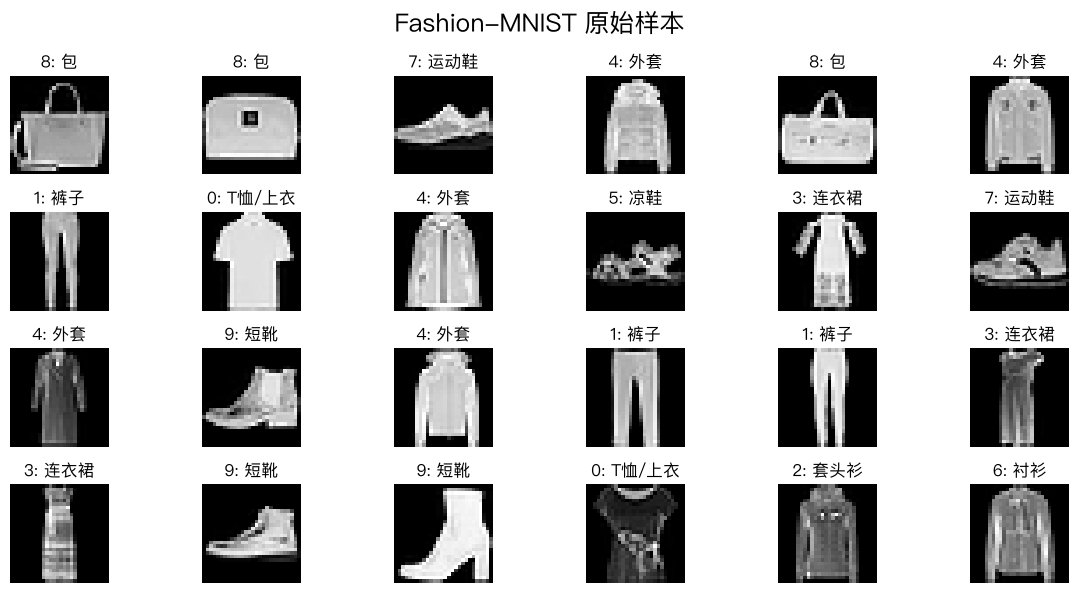

In [5]:
# ============================================================
# 第 2 步：展示一批 Fashion-MNIST 原始图片
# ============================================================

# 从训练集中随机抽取 24 张图片。
sample_indices = np.random.choice(len(x_train_full), size=24, replace=False)

plt.figure(figsize=(12, 6))

for i, idx in enumerate(sample_indices):
    plt.subplot(4, 6, i + 1)

    # Fashion-MNIST 是灰度图，因此使用 cmap="gray"。
    plt.imshow(x_train_full[idx], cmap="gray")

    # 根据标签编号找到类别名称。
    label = y_train_full[idx]
    plt.title(f"{label}: {class_names[label]}")

    # 隐藏坐标轴，使图片更清晰。
    plt.axis("off")

plt.suptitle("Fashion-MNIST 原始样本", fontsize=18)
plt.tight_layout()
plt.show()

# 第 3 步：观察标签分布

在分类任务中，最好先看一下每个类别的数据数量。

如果某些类别特别多，某些类别特别少，模型可能会偏向数据更多的类别。  
这叫做类别不平衡。

Fashion-MNIST 的类别分布通常比较均衡。

训练集中每个类别的图片数量：
0: T恤/上衣 -> 6000 张
1: 裤子 -> 6000 张
2: 套头衫 -> 6000 张
3: 连衣裙 -> 6000 张
4: 外套 -> 6000 张
5: 凉鞋 -> 6000 张
6: 衬衫 -> 6000 张
7: 运动鞋 -> 6000 张
8: 包 -> 6000 张
9: 短靴 -> 6000 张


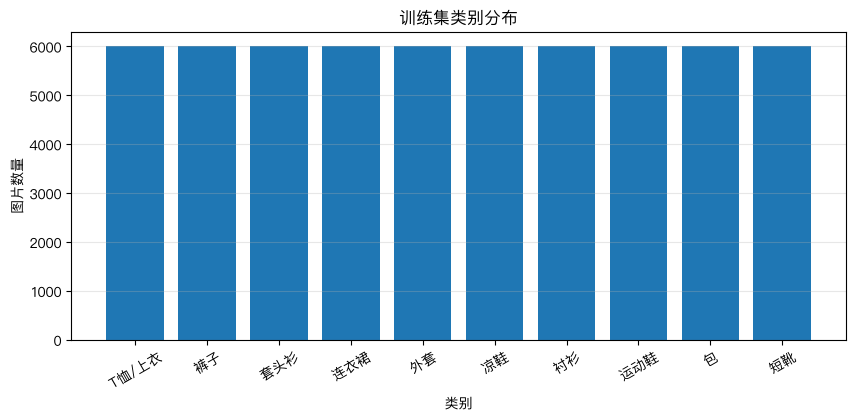

In [6]:
# ============================================================
# 第 3 步：观察训练集标签分布
# ============================================================

# np.bincount 可以统计每个整数标签出现的次数。
label_counts = np.bincount(y_train_full)

print("训练集中每个类别的图片数量：")
for label, count in enumerate(label_counts):
    print(f"{label}: {class_names[label]} -> {count} 张")

plt.figure(figsize=(10, 4))
plt.bar(range(10), label_counts)
plt.xticks(range(10), class_names, rotation=30)
plt.title("训练集类别分布")
plt.xlabel("类别")
plt.ylabel("图片数量")
plt.grid(axis="y", alpha=0.3)
plt.show()

# 第 4 步：观察一张图片背后的像素矩阵

你看到的是一张服饰图片。  
计算机看到的是一个 28×28 的数字矩阵。

每个数字代表一个像素点的亮度：

```text
0   表示黑色
255 表示白色
中间值表示不同程度的灰色
```

所以，图像识别本质上并不是模型直接“看懂”了物体，  
而是模型从大量像素数值中学习不同类别的分布规律。

当前观察的是第 0 张训练图片。
标签编号： 9
类别名称： 短靴
图片形状： (28, 28)

这张图片对应的 28×28 像素矩阵如下：
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0
    0   1   4   0   0   0   0   1   1   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62
   54   0   0   0   1   3   4   0   0   3]
 [  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134
  144 123  23   0   0   0   0  12  10   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178
  107 156 161 109  64  23  77 130  72  15]
 [  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216
  216 163 127 121 122 146 141  88 1

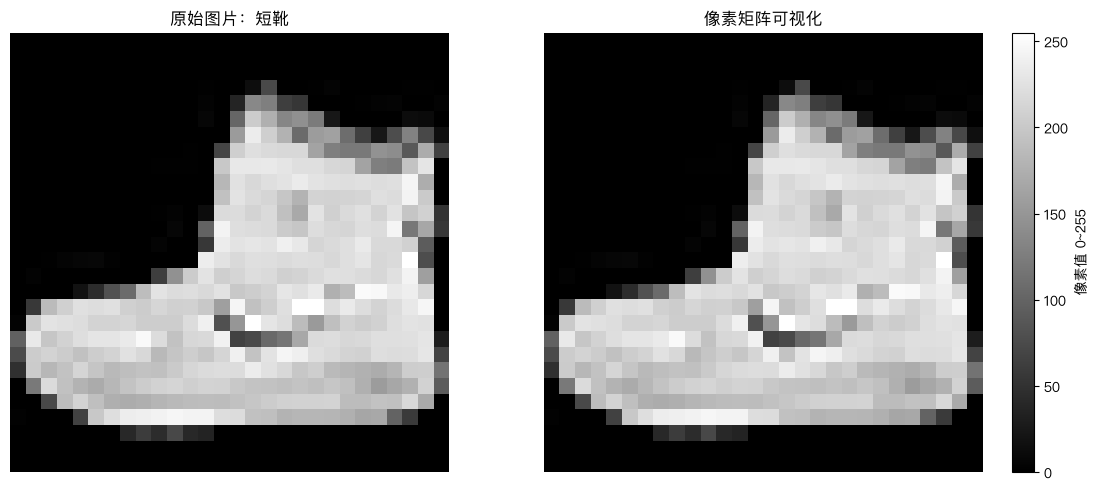

In [7]:
# ============================================================
# 第 4 步：选择一张图片，观察它背后的像素矩阵
# ============================================================

# 选择第 0 张训练图片进行观察。
example_index = 0

example_image = x_train_full[example_index]
example_label = y_train_full[example_index]
example_class_name = class_names[example_label]

print(f"当前观察的是第 {example_index} 张训练图片。")
print("标签编号：", example_label)
print("类别名称：", example_class_name)
print("图片形状：", example_image.shape)

print("\n这张图片对应的 28×28 像素矩阵如下：")
print(example_image)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(example_image, cmap="gray")
plt.title(f"原始图片：{example_class_name}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(example_image, cmap="gray")
plt.title("像素矩阵可视化")
plt.colorbar(label="像素值 0~255")
plt.axis("off")

plt.tight_layout()
plt.show()

# 第 5 步：放大显示像素值

这一部分用于直观看到每个像素点的数值。

由于 28×28 一共有 784 个像素，全部显示会比较密集。  
下面只显示非零像素，便于观察服饰轮廓。

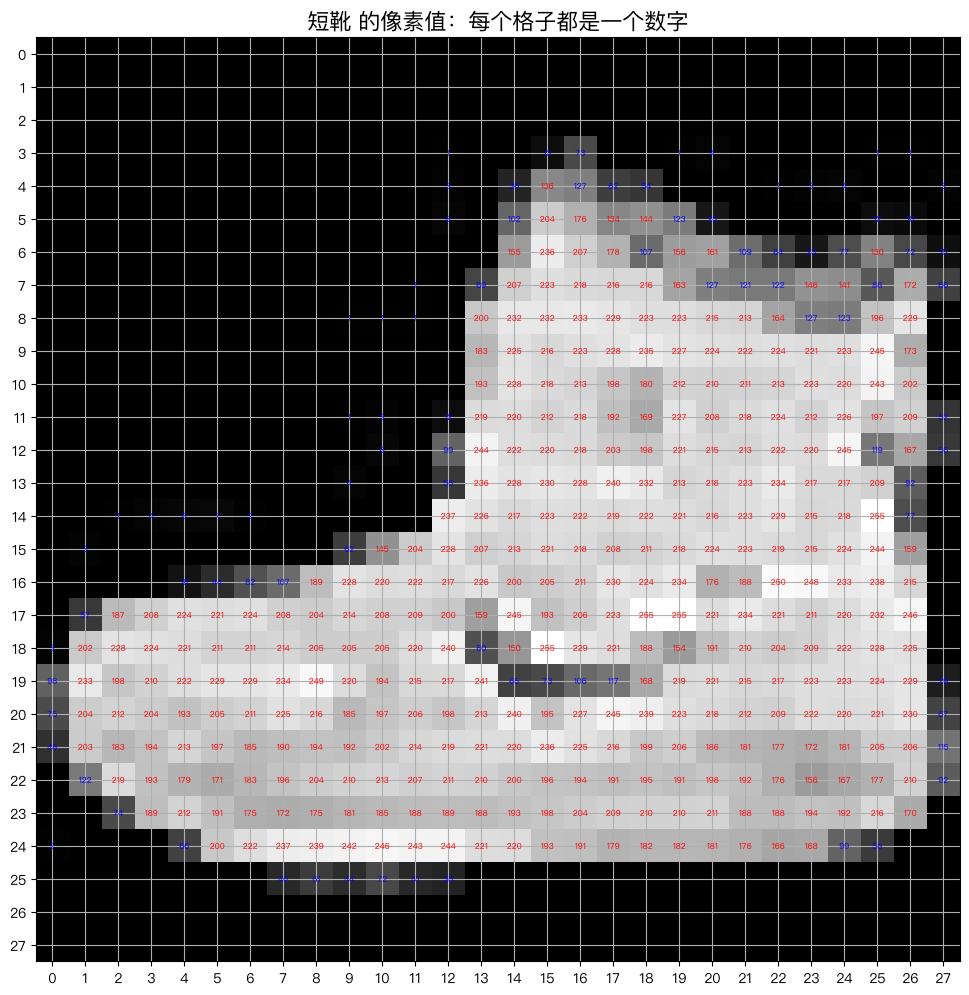

In [8]:
# ============================================================
# 第 5 步：放大图片，并标出非零像素值
# ============================================================

plt.figure(figsize=(12, 12))
plt.imshow(example_image, cmap="gray")

for row in range(28):
    for col in range(28):
        value = example_image[row, col]

        # 只显示非零像素，避免文字过于密集。
        if value > 0:
            plt.text(
                col,
                row,
                str(value),
                ha="center",
                va="center",
                fontsize=6,
                color="red" if value > 128 else "blue"
            )

plt.title(f"{example_class_name} 的像素值：每个格子都是一个数字", fontsize=16)
plt.xticks(range(28))
plt.yticks(range(28))
plt.grid()
plt.show()

# 第 6 步：数据归一化

原始像素值范围是：

```text
0 到 255
```

神经网络训练时通常更适合处理较小、稳定的数值范围。  
因此我们把像素值除以 255，使其变成：

```text
0 到 1
```

例如：

```text
0   / 255 = 0
128 / 255 ≈ 0.502
255 / 255 = 1
```

归一化前：
最小值： 0
最大值： 255

归一化后：
最小值： 0.0
最大值： 1.0


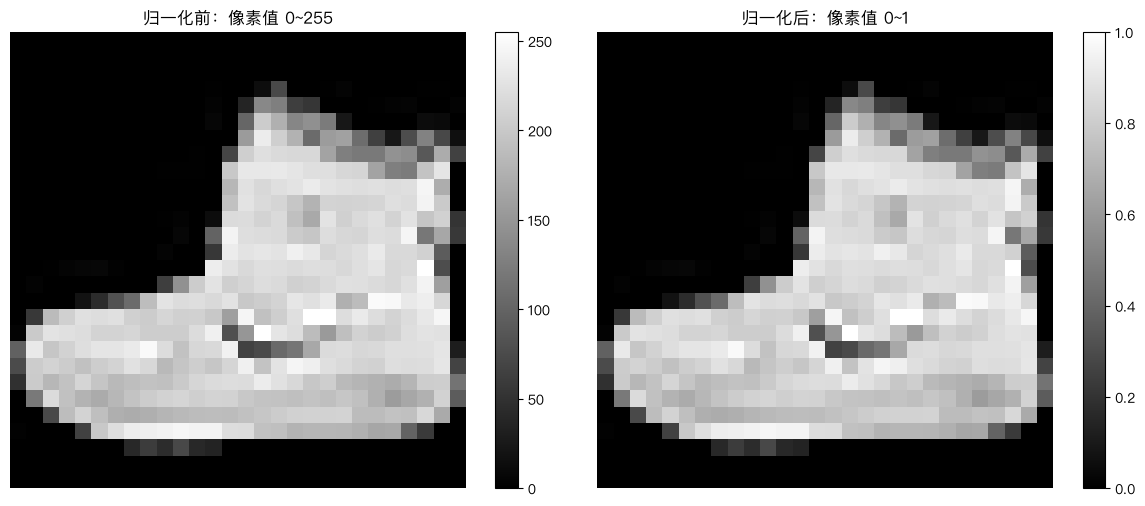

In [9]:
# ============================================================
# 第 6 步：数据归一化，把像素值从 0~255 转换到 0~1
# ============================================================

# astype("float32")：
# 把整数类型转换为浮点数类型。
#
# / 255.0：
# 把像素值缩放到 0~1。
x_train_full_normalized = x_train_full.astype("float32") / 255.0
x_test_normalized = x_test.astype("float32") / 255.0

example_image_normalized = x_train_full_normalized[example_index]

print("归一化前：")
print("最小值：", example_image.min())
print("最大值：", example_image.max())

print("\n归一化后：")
print("最小值：", example_image_normalized.min())
print("最大值：", example_image_normalized.max())

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(example_image, cmap="gray")
plt.title("归一化前：像素值 0~255")
plt.colorbar()
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(example_image_normalized, cmap="gray")
plt.title("归一化后：像素值 0~1")
plt.colorbar()
plt.axis("off")

plt.tight_layout()
plt.show()

# 第 7 步：拆分训练集和验证集

原始数据已经分成训练集和测试集。  
为了在训练过程中观察模型对新数据的表现，我们从训练集中再分出一部分作为验证集。

最终会有三部分：

| 数据集 | 作用 |
|---|---|
| 训练集 | 用来调整模型参数 |
| 验证集 | 训练过程中观察模型表现 |
| 测试集 | 训练结束后进行最终评估 |

测试集不要参与训练过程，否则最终评估会不够客观。

In [10]:
# ============================================================
# 第 7 步：拆分训练集和验证集
# ============================================================

# 生成随机排列的索引，用于打乱数据顺序。
indices = np.random.permutation(len(x_train_full_normalized))

# 按照随机索引重新排列图片和标签。
x_train_full_normalized = x_train_full_normalized[indices]
y_train_full = y_train_full[indices]

# 从 60000 张训练图片中取最后 10000 张作为验证集。
x_val = x_train_full_normalized[-10000:]
y_val = y_train_full[-10000:]

# 前 50000 张作为真正用于参数更新的训练集。
x_train = x_train_full_normalized[:-10000]
y_train = y_train_full[:-10000]

print("训练集图片形状：", x_train.shape)
print("训练集标签形状：", y_train.shape)
print("验证集图片形状：", x_val.shape)
print("验证集标签形状：", y_val.shape)
print("测试集图片形状：", x_test_normalized.shape)
print("测试集标签形状：", y_test.shape)

训练集图片形状： (50000, 28, 28)
训练集标签形状： (50000,)
验证集图片形状： (10000, 28, 28)
验证集标签形状： (10000,)
测试集图片形状： (10000, 28, 28)
测试集标签形状： (10000,)


# 第 8 步：理解标签和 one-hot 编码

Fashion-MNIST 的原始标签是整数，例如：

```text
9
```

表示类别编号为 9，也就是短靴。

在分类任务中，你也可能看到 one-hot 编码。  
例如标签 9 可以表示成：

```text
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]
```

不过本案例训练时使用：

```python
sparse_categorical_crossentropy
```

这个损失函数可以直接接收整数标签，因此不需要手动转换成 one-hot。

原始标签编号： 9
类别名称： 短靴
one-hot 编码： [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


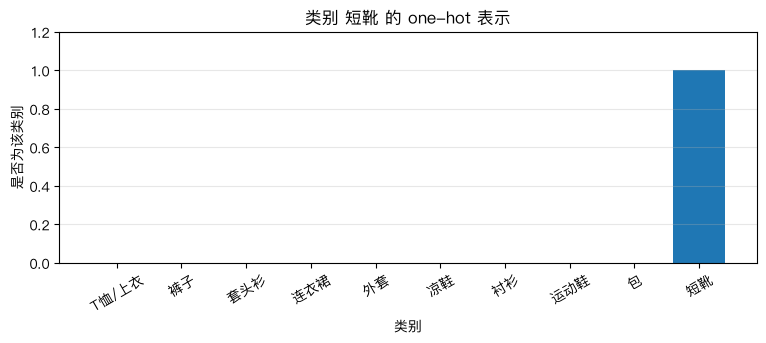

In [11]:
# ============================================================
# 第 8 步：展示标签和 one-hot 编码
# ============================================================

one_hot_example = keras.utils.to_categorical(example_label, num_classes=10)

print("原始标签编号：", example_label)
print("类别名称：", class_names[example_label])
print("one-hot 编码：", one_hot_example)

plt.figure(figsize=(9, 3))
plt.bar(range(10), one_hot_example)
plt.xticks(range(10), class_names, rotation=30)
plt.ylim(0, 1.2)
plt.title(f"类别 {class_names[example_label]} 的 one-hot 表示")
plt.xlabel("类别")
plt.ylabel("是否为该类别")
plt.grid(axis="y", alpha=0.3)
plt.show()

# 第 9 步：理解 Flatten

每张图片原本是：

```text
28 × 28
```

普通全连接神经网络接收的是一排输入特征。  
因此需要把二维矩阵拉平成一维向量：

```text
28 × 28 = 784
```

这个过程叫做 Flatten。

也就是说，一张服饰图片会变成 784 个输入特征，  
每个特征都是一个像素点的灰度值。

原始图片形状： (28, 28)
Flatten 后形状： (784,)

Flatten 后的前 40 个像素值：
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


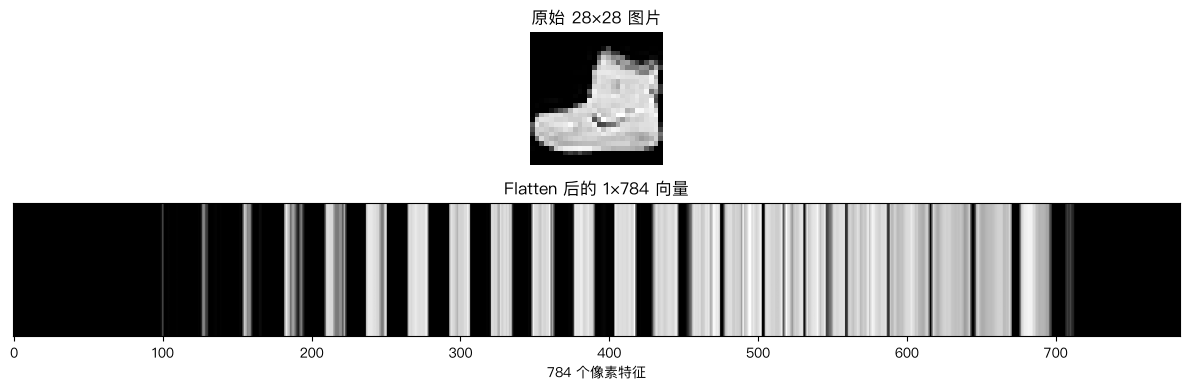

In [12]:
# ============================================================
# 第 9 步：Flatten，把 28×28 矩阵拉平成 784 个数字
# ============================================================

flatten_example = example_image_normalized.reshape(-1)

print("原始图片形状：", example_image_normalized.shape)
print("Flatten 后形状：", flatten_example.shape)

print("\nFlatten 后的前 40 个像素值：")
print(flatten_example[:40])

plt.figure(figsize=(12, 4))

plt.subplot(2, 1, 1)
plt.imshow(example_image_normalized, cmap="gray")
plt.title("原始 28×28 图片")
plt.axis("off")

plt.subplot(2, 1, 2)
plt.imshow(flatten_example.reshape(1, 784), cmap="gray", aspect="auto")
plt.title("Flatten 后的 1×784 向量")
plt.yticks([])
plt.xlabel("784 个像素特征")

plt.tight_layout()
plt.show()

# 第 10 步：构建神经网络模型

这个模型结构如下：

```text
输入：28×28 图像
        ↓
Flatten：拉平成 784 个数字
        ↓
Dense：256 个神经元，ReLU 激活
        ↓
Dropout：随机丢弃 30%
        ↓
Dense：128 个神经元，ReLU 激活
        ↓
Dropout：随机丢弃 20%
        ↓
Dense：10 个神经元，Softmax 输出概率
```

和手写数字识别相比，Fashion-MNIST 通常更难一些，  
因为服饰类别之间可能更相似，例如：

- T恤 / 上衣 和 衬衫
- 套头衫 和 外套
- 运动鞋 和 短靴

所以这里使用了两个隐藏层。

In [13]:
# ============================================================
# 第 10 步：构建神经网络模型
# ============================================================

# ------------------------------------------------------------
# 注意：
# Keras 层的 name 使用英文安全命名。
# 中文解释写在注释、Markdown、print 或图表标题中。
# ------------------------------------------------------------

model = keras.Sequential([
    # 输入层：
    # 每个样本是一张 28×28 的灰度图片。
    layers.Input(shape=(28, 28), name="input_28x28_image"),

    # Flatten 层：
    # 把 28×28 的二维图像拉平成 784 个输入特征。
    layers.Flatten(name="flatten_28x28_to_784"),

    # 第一个全连接隐藏层：
    # 256 个神经元，使用 ReLU 激活函数。
    # 神经元数量比 MNIST 示例略多，因为服饰分类更复杂。
    layers.Dense(256, activation="relu", name="dense_256_relu"),

    # Dropout 层：
    # 每次训练时随机让 30% 的神经元暂时失效。
    # 这样可以降低模型死记训练数据的风险。
    layers.Dropout(0.3, name="dropout_30_percent"),

    # 第二个全连接隐藏层：
    # 128 个神经元，继续提取更抽象的特征组合。
    layers.Dense(128, activation="relu", name="dense_128_relu"),

    # 再加一层 Dropout：
    # 进一步降低过拟合风险。
    layers.Dropout(0.2, name="dropout_20_percent"),

    # 输出层：
    # 10 个神经元对应 10 个服饰类别。
    # Softmax 会把输出转换成 10 个概率。
    layers.Dense(10, activation="softmax", name="output_10_softmax")
])

# 编译模型。
#
# optimizer="adam"：
# 使用 Adam 优化器自动调整模型参数。
#
# loss="sparse_categorical_crossentropy"：
# 适用于多分类任务，并且标签是整数编号。
#
# metrics=["accuracy"]：
# 训练过程中显示准确率。
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_28x28_to_784 (Flatten)  │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256_relu (Dense)          │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30_percent (Dropout)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128_relu (Dense)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20_percent (Dropout)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_10_softmax (Dense)       │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

# 第 10.1 步：理解参数数量

在 `model.summary()` 中可以看到每一层的参数数量。

第一层 Dense 接收 784 个输入特征，输出 256 个神经元：

```text
权重数量 = 784 × 256
偏置数量 = 256
总参数数量 = 784 × 256 + 256
```

这些参数一开始通常是随机的。  
训练过程就是不断调整这些参数，让模型预测更接近真实标签。

In [14]:
# ============================================================
# 第 10.1 步：手动计算第一层 Dense 的参数数量
# ============================================================

input_features = 28 * 28
first_hidden_neurons = 256

weight_count = input_features * first_hidden_neurons
bias_count = first_hidden_neurons
total_count = weight_count + bias_count

print("输入特征数：", input_features)
print("第一层隐藏神经元数量：", first_hidden_neurons)
print("权重数量 = 784 × 256 =", weight_count)
print("偏置数量 = 256")
print("总参数数量 =", total_count)

输入特征数： 784
第一层隐藏神经元数量： 256
权重数量 = 784 × 256 = 200704
偏置数量 = 256
总参数数量 = 200960


# 第 11 步：训练模型

训练时，每一轮 `epoch` 大致会发生：

1. 模型读取一批图片。
2. 根据当前参数输出预测概率。
3. 将预测结果和真实标签进行比较。
4. 计算损失值。
5. 通过反向传播计算参数应该如何调整。
6. 优化器更新参数。
7. 重复以上过程。

---

## batch_size

```python
batch_size=128
```

表示每次使用 128 张图片来计算一次参数更新。

---

## epochs

```python
epochs=10
```

表示完整训练集会被模型学习 10 遍。

In [15]:
# ============================================================
# 第 11 步：开始训练模型
# ============================================================

# Fashion-MNIST 比 MNIST 稍难一些，因此这里训练 10 轮。
# 如果你希望运行更快，可以把 EPOCHS 改成 5。
EPOCHS = 10
BATCH_SIZE = 128

history = model.fit(
    x_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_val, y_val)
)

Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7770 - loss: 0.6260 - val_accuracy: 0.8403 - val_loss: 0.4511
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8436 - loss: 0.4339 - val_accuracy: 0.8562 - val_loss: 0.3947
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8561 - loss: 0.3968 - val_accuracy: 0.8637 - val_loss: 0.3699
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8662 - loss: 0.3691 - val_accuracy: 0.8679 - val_loss: 0.3555
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8710 - loss: 0.3495 - val_accuracy: 0.8742 - val_loss: 0.3499
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8761 - loss: 0.3371 - val_accuracy: 0.8737 - val_loss: 0.3448
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8791 - loss: 0.3237 - val_accuracy: 0.8758 - val_loss: 0.3344
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8846 - loss: 0.3126 - val_accuracy: 0.

# 第 12 步：绘制训练过程曲线

训练结束后，需要观察两个重要指标：

1. `loss`：损失值，越低通常越好。
2. `accuracy`：准确率，越高通常越好。

同时观察训练集和验证集：

- 训练集表现好，说明模型能拟合已见过的数据。
- 验证集表现好，说明模型对新数据也有较好效果。
- 如果训练集越来越好，但验证集变差，可能出现了过拟合。

history 中包含的指标： dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


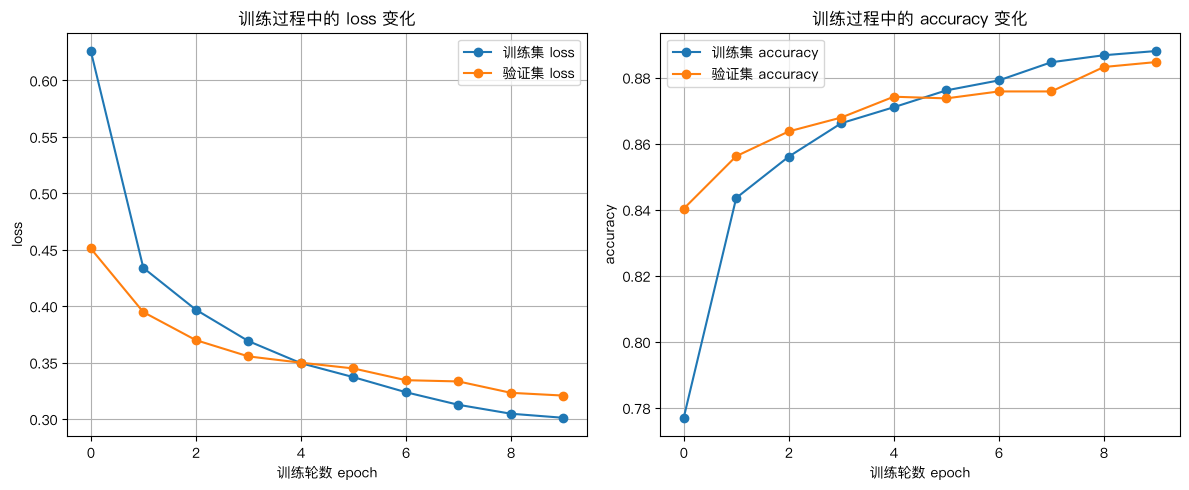

观察建议：
1. loss 越低，表示预测和真实答案之间的差距越小。
2. accuracy 越高，表示分类正确率越高。
3. 如果训练集很好但验证集变差，可能说明过拟合。


In [16]:
# ============================================================
# 第 12 步：绘制 loss 和 accuracy 变化曲线
# ============================================================

history_dict = history.history

print("history 中包含的指标：", history_dict.keys())

plt.figure(figsize=(12, 5))

# 左图：loss 变化。
plt.subplot(1, 2, 1)
plt.plot(history_dict["loss"], marker="o", label="训练集 loss")
plt.plot(history_dict["val_loss"], marker="o", label="验证集 loss")
plt.title("训练过程中的 loss 变化")
plt.xlabel("训练轮数 epoch")
plt.ylabel("loss")
plt.legend()
plt.grid(True)

# 右图：accuracy 变化。
plt.subplot(1, 2, 2)
plt.plot(history_dict["accuracy"], marker="o", label="训练集 accuracy")
plt.plot(history_dict["val_accuracy"], marker="o", label="验证集 accuracy")
plt.title("训练过程中的 accuracy 变化")
plt.xlabel("训练轮数 epoch")
plt.ylabel("accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("观察建议：")
print("1. loss 越低，表示预测和真实答案之间的差距越小。")
print("2. accuracy 越高，表示分类正确率越高。")
print("3. 如果训练集很好但验证集变差，可能说明过拟合。")

# 第 13 步：在测试集上评估模型

测试集没有参与训练过程。  
因此测试集结果更能反映模型面对新图片时的表现。

这里会输出：

- 测试集 loss
- 测试集 accuracy

In [17]:
# ============================================================
# 第 13 步：使用测试集评估模型
# ============================================================

test_loss, test_accuracy = model.evaluate(x_test_normalized, y_test, verbose=0)

print(f"测试集 loss：{test_loss:.4f}")
print(f"测试集 accuracy：{test_accuracy:.4f}")
print(f"测试集准确率约为：{test_accuracy * 100:.2f}%")

测试集 loss：0.3437
测试集 accuracy：0.8744
测试集准确率约为：87.44%


# 第 14 步：观察单张图片的预测过程

模型最后输出 10 个概率。  
每个概率对应一个类别。

例如：

```text
T恤/上衣：0.03
裤子：0.01
套头衫：0.02
...
短靴：0.91
```

概率最大的类别，就是模型最终预测的类别。

真实标签编号： 9
真实类别名称： 短靴
预测标签编号： 9
预测类别名称： 短靴

模型输出的 10 个概率：
0: T恤/上衣 -> 0.0000
1: 裤子 -> 0.0001
2: 套头衫 -> 0.0000
3: 连衣裙 -> 0.0000
4: 外套 -> 0.0000
5: 凉鞋 -> 0.0139
6: 衬衫 -> 0.0000
7: 运动鞋 -> 0.0403
8: 包 -> 0.0000
9: 短靴 -> 0.9456


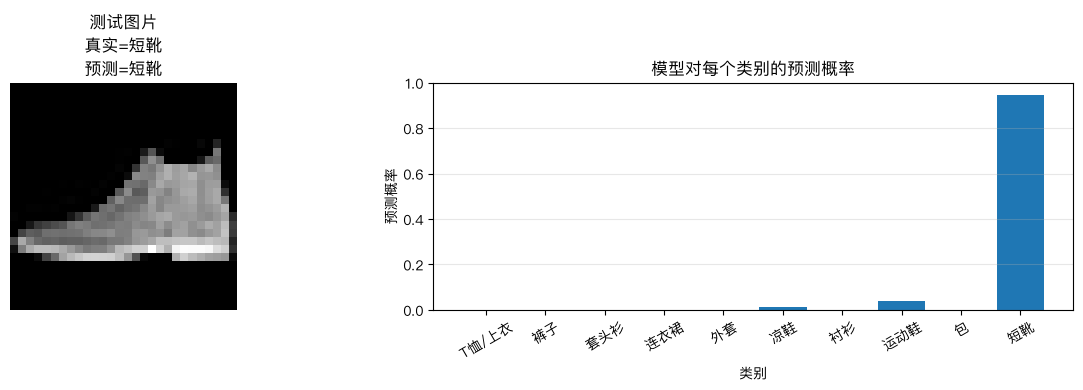

In [18]:
# ============================================================
# 第 14 步：观察模型对单张图片的预测过程
# ============================================================

# 选择测试集中的一张图片。
test_index = 0

single_image = x_test_normalized[test_index]
single_label = y_test[test_index]
single_class_name = class_names[single_label]

# model.predict 需要接收一批数据。
# single_image 原本是 (28, 28)
# reshape(1, 28, 28) 后表示这一批中有 1 张图片。
single_prediction = model.predict(single_image.reshape(1, 28, 28), verbose=0)[0]

# 概率最大的下标就是预测标签。
predicted_label = np.argmax(single_prediction)
predicted_class_name = class_names[predicted_label]

print("真实标签编号：", single_label)
print("真实类别名称：", single_class_name)
print("预测标签编号：", predicted_label)
print("预测类别名称：", predicted_class_name)

print("\n模型输出的 10 个概率：")
for index, prob in enumerate(single_prediction):
    print(f"{index}: {class_names[index]} -> {prob:.4f}")

plt.figure(figsize=(13, 4))

plt.subplot(1, 2, 1)
plt.imshow(single_image, cmap="gray")
plt.title(f"测试图片\n真实={single_class_name}\n预测={predicted_class_name}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.bar(range(10), single_prediction)
plt.xticks(range(10), class_names, rotation=30)
plt.ylim(0, 1)
plt.title("模型对每个类别的预测概率")
plt.xlabel("类别")
plt.ylabel("预测概率")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# 第 15 步：批量展示预测结果

下面展示测试集中前 30 张图片的预测结果。

标题含义：

```text
真：真实类别
预：预测类别
```

颜色含义：

- 绿色：预测正确
- 红色：预测错误

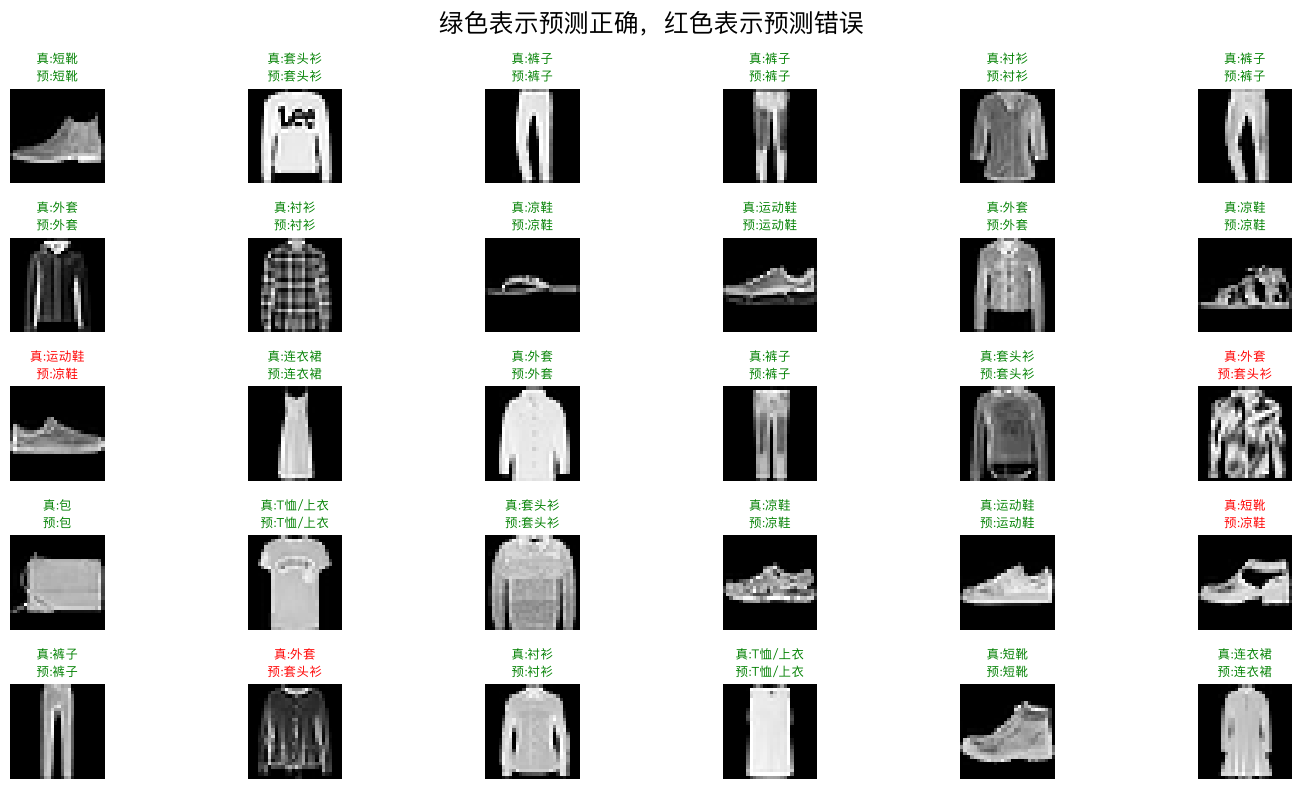

In [19]:
# ============================================================
# 第 15 步：批量展示测试集预测结果
# ============================================================

num_show = 30

# 对前 30 张测试图片进行预测。
predictions = model.predict(x_test_normalized[:num_show], verbose=0)

# 取每张图片概率最大的类别作为预测结果。
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(15, 8))

for i in range(num_show):
    plt.subplot(5, 6, i + 1)
    plt.imshow(x_test_normalized[i], cmap="gray")

    true_label = y_test[i]
    pred_label = predicted_labels[i]

    true_name = class_names[true_label]
    pred_name = class_names[pred_label]

    title_color = "green" if true_label == pred_label else "red"

    plt.title(
        f"真:{true_name}\n预:{pred_name}",
        color=title_color,
        fontsize=9
    )
    plt.axis("off")

plt.suptitle("绿色表示预测正确，红色表示预测错误", fontsize=18)
plt.tight_layout()
plt.show()

# 第 16 步：混淆矩阵

混淆矩阵可以用来分析模型容易混淆哪些类别。

矩阵含义：

```text
行：真实类别
列：预测类别
```

例如：

```text
真实类别是 T恤/上衣，经常被预测成 衬衫
```

说明这两个类别在像素形状上比较相似，模型更容易混淆。

混淆矩阵：
[[772   1  18  63   2   1 134   0   9   0]
 [  1 969   0  24   1   0   2   1   2   0]
 [  7   1 823  21  63   0  84   0   1   0]
 [ 10   7   7 942  10   0  20   0   4   0]
 [  0   1 152  71 686   0  89   0   1   0]
 [  0   0   0   0   0 961   0  24   1  14]
 [ 96   1  85  61  43   0 701   0  13   0]
 [  0   0   0   0   0  15   0 959   0  26]
 [  2   1   7   5   3   2   4   2 974   0]
 [  0   0   0   0   0   7   1  35   0 957]]


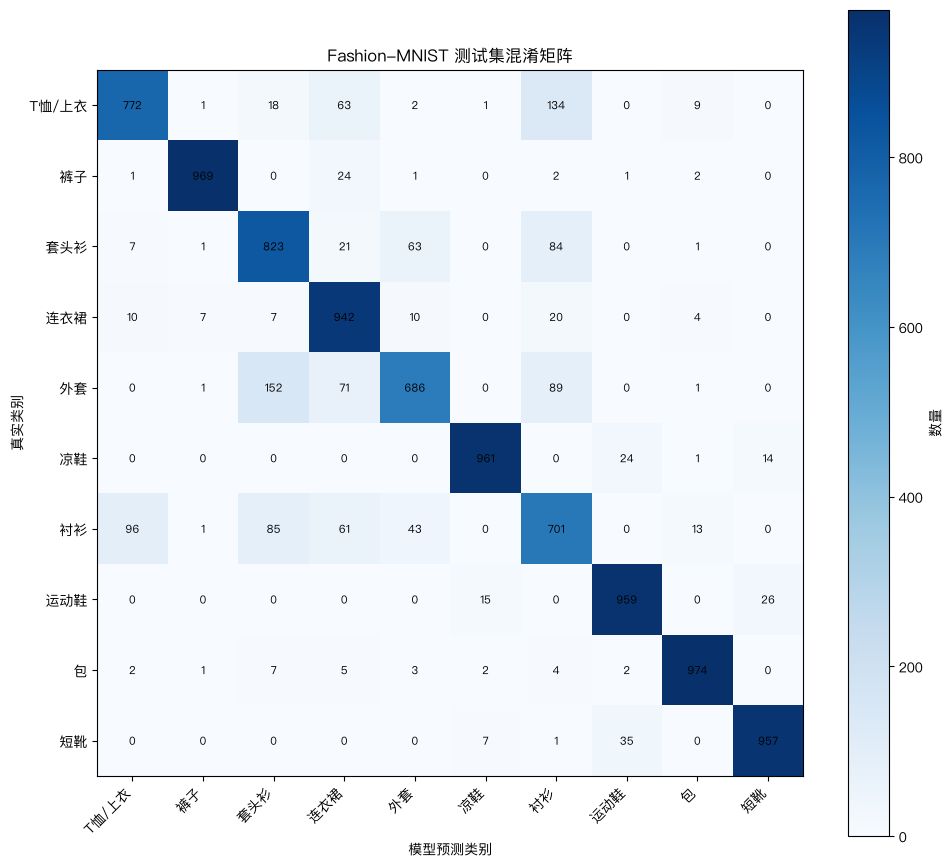

In [20]:
# ============================================================
# 第 16 步：计算并展示混淆矩阵
# ============================================================

# 对整个测试集进行预测。
all_predictions = model.predict(x_test_normalized, verbose=0)
all_predicted_labels = np.argmax(all_predictions, axis=1)

# 创建一个 10×10 的矩阵。
# 行表示真实类别，列表示预测类别。
confusion_matrix = np.zeros((10, 10), dtype=int)

# 统计每种真实类别和预测类别的组合出现次数。
for true_label, pred_label in zip(y_test, all_predicted_labels):
    confusion_matrix[true_label, pred_label] += 1

print("混淆矩阵：")
print(confusion_matrix)

plt.figure(figsize=(10, 9))
plt.imshow(confusion_matrix, cmap="Blues")
plt.title("Fashion-MNIST 测试集混淆矩阵")
plt.xlabel("模型预测类别")
plt.ylabel("真实类别")
plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)
plt.colorbar(label="数量")

# 在每个格子里写上数量。
for row in range(10):
    for col in range(10):
        plt.text(
            col,
            row,
            str(confusion_matrix[row, col]),
            ha="center",
            va="center",
            color="black",
            fontsize=8
        )

plt.tight_layout()
plt.show()

# 第 17 步：找出最容易混淆的类别

混淆矩阵里，对角线表示预测正确的数量。  
非对角线表示预测错误的数量。

下面会找出非对角线中数量最多的几个错误组合。  
这可以帮助你理解模型主要错在哪里。

In [21]:
# ============================================================
# 第 17 步：分析最常见的错误组合
# ============================================================

# 复制一份混淆矩阵，避免修改原矩阵。
cm_without_diagonal = confusion_matrix.copy()

# 把对角线清零。
# 对角线表示预测正确，不属于错误组合。
np.fill_diagonal(cm_without_diagonal, 0)

# 找出错误次数最多的前 10 个组合。
error_pairs = []

for true_label in range(10):
    for pred_label in range(10):
        count = cm_without_diagonal[true_label, pred_label]
        if count > 0:
            error_pairs.append((count, true_label, pred_label))

# 按错误次数从大到小排序。
error_pairs.sort(reverse=True)

print("最常见的错误组合：")
for rank, (count, true_label, pred_label) in enumerate(error_pairs[:10], start=1):
    print(
        f"{rank}. 真实={class_names[true_label]}，"
        f"预测={class_names[pred_label]}，"
        f"次数={count}"
    )

最常见的错误组合：
1. 真实=外套，预测=套头衫，次数=152
2. 真实=T恤/上衣，预测=衬衫，次数=134
3. 真实=衬衫，预测=T恤/上衣，次数=96
4. 真实=外套，预测=衬衫，次数=89
5. 真实=衬衫，预测=套头衫，次数=85
6. 真实=套头衫，预测=衬衫，次数=84
7. 真实=外套，预测=连衣裙，次数=71
8. 真实=套头衫，预测=外套，次数=63
9. 真实=T恤/上衣，预测=连衣裙，次数=63
10. 真实=衬衫，预测=连衣裙，次数=61


# 第 18 步：展示预测错误的图片

只看数字指标还不够。  
直接观察错误图片，可以帮助你理解模型为什么会犯错。

常见原因包括：

1. 图片本身轮廓模糊。
2. 类别之间外形相似。
3. 服饰姿态、宽窄、边缘形状差异较大。
4. 这个模型是全连接网络，没有专门利用图像局部结构。

测试集中一共有 10000 张图片。
模型预测错误的图片数量：1256
错误率约为：12.56%


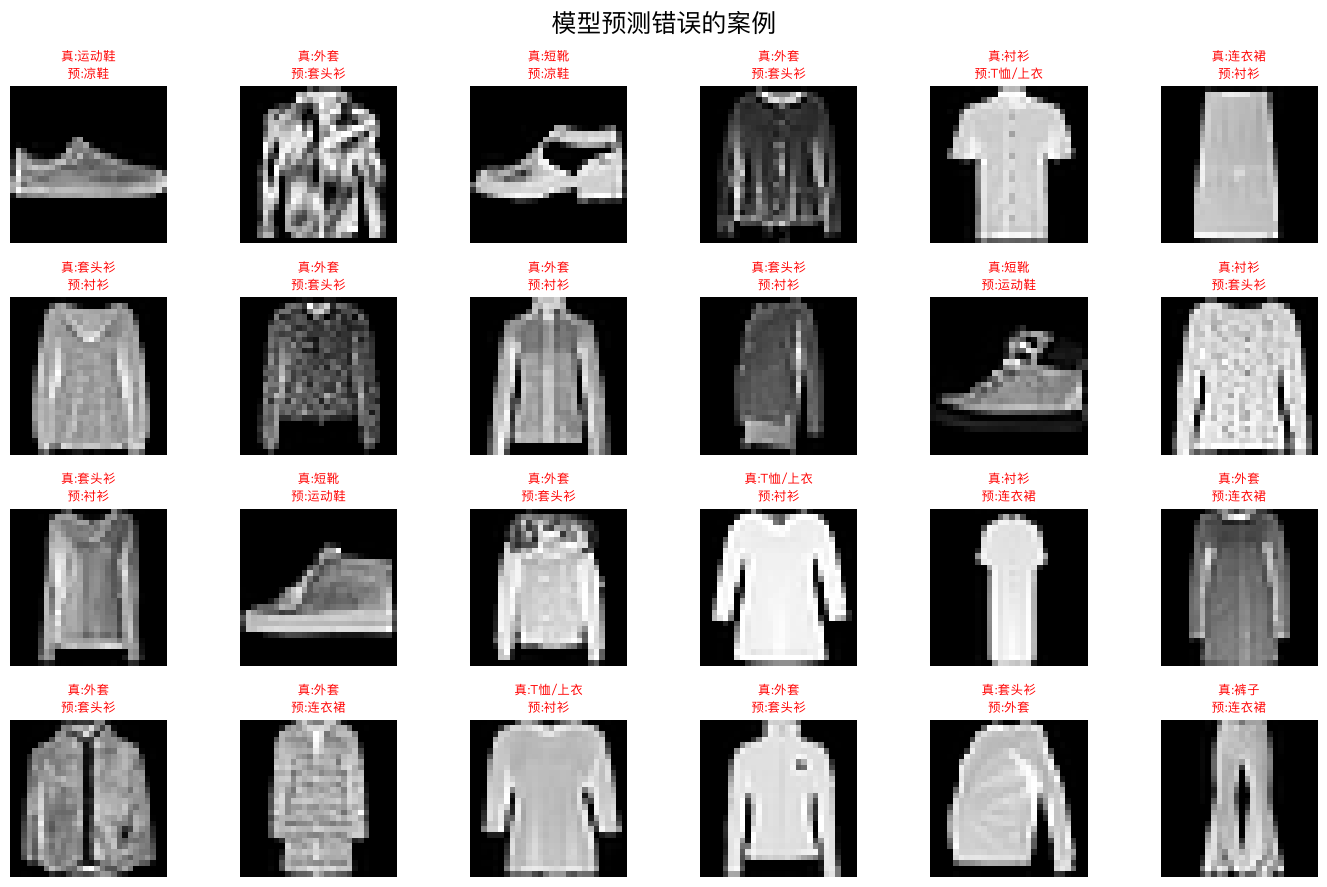

In [22]:
# ============================================================
# 第 18 步：展示模型预测错误的图片
# ============================================================

wrong_indices = np.where(all_predicted_labels != y_test)[0]

print(f"测试集中一共有 {len(y_test)} 张图片。")
print(f"模型预测错误的图片数量：{len(wrong_indices)}")
print(f"错误率约为：{len(wrong_indices) / len(y_test) * 100:.2f}%")

num_wrong_show = min(24, len(wrong_indices))

plt.figure(figsize=(14, 9))

for i in range(num_wrong_show):
    idx = wrong_indices[i]

    plt.subplot(4, 6, i + 1)
    plt.imshow(x_test_normalized[idx], cmap="gray")

    true_label = y_test[idx]
    pred_label = all_predicted_labels[idx]

    true_name = class_names[true_label]
    pred_name = class_names[pred_label]

    plt.title(f"真:{true_name}\n预:{pred_name}", color="red", fontsize=9)
    plt.axis("off")

plt.suptitle("模型预测错误的案例", fontsize=18)
plt.tight_layout()
plt.show()

# 第 19 步：观察 Softmax 概率分布

对于一张图片，模型不只是给出一个类别，  
它实际上会输出 10 个类别的概率。

如果最高概率明显高于其他类别，说明模型比较“确定”。  
如果多个类别概率接近，说明模型比较“犹豫”。

下面展示几张图片及其 Softmax 概率分布。

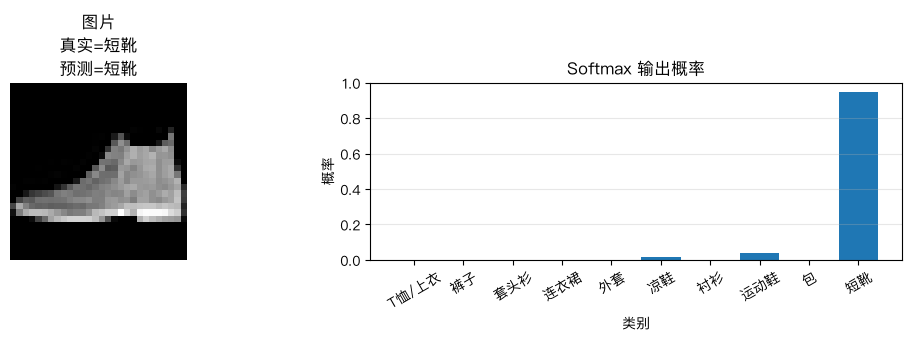

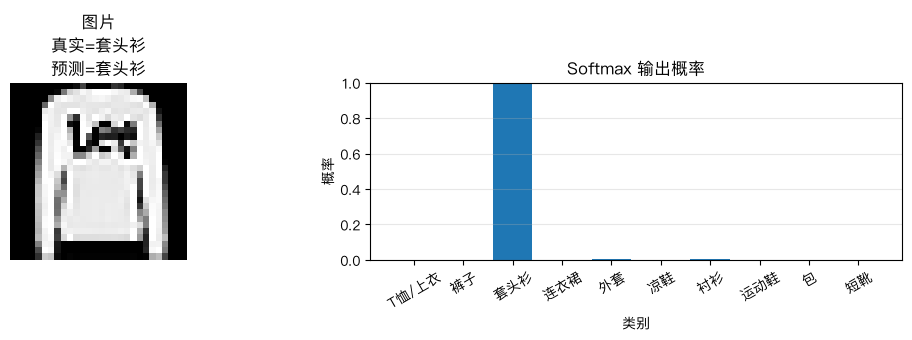

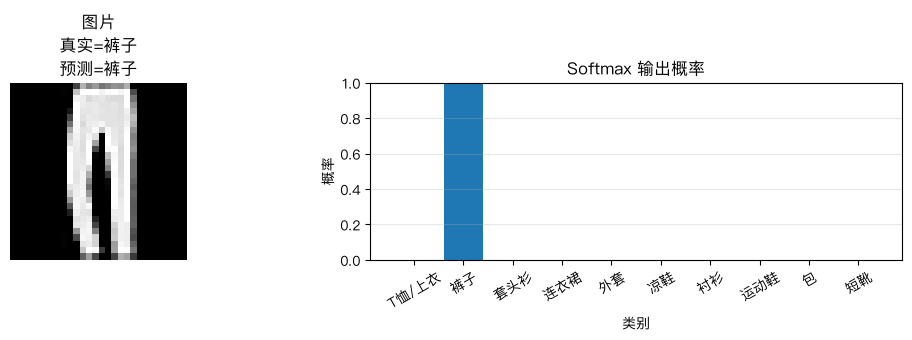

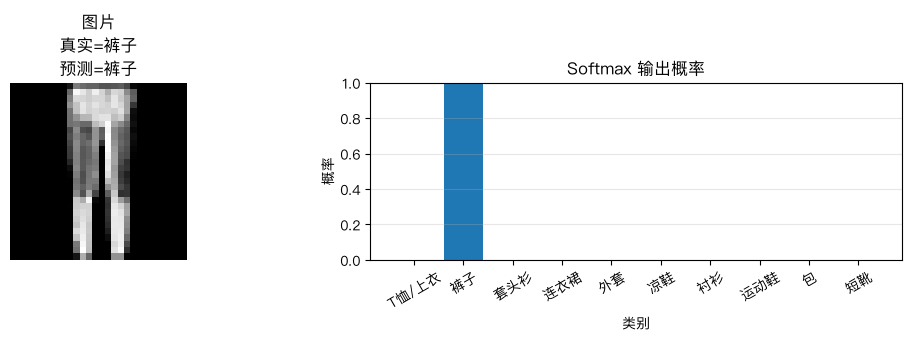

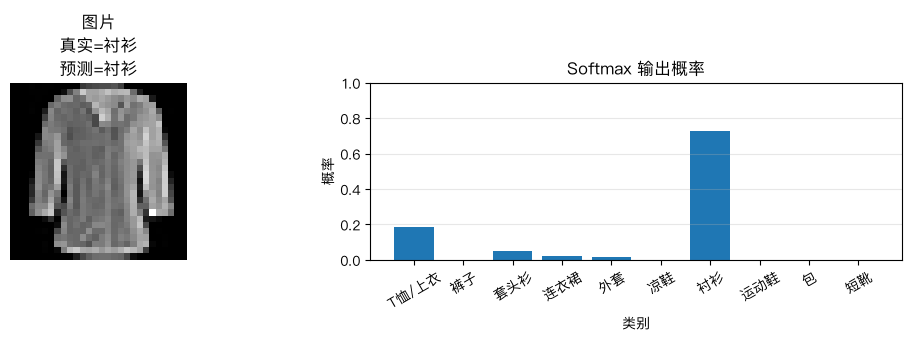

In [ ]:
# ============================================================
# 第 19 步：展示多张图片的 Softmax 概率分布
# ============================================================

indices_to_show = [0, 1, 2, 3, 4]



for idx in indices_to_show:
    image = x_test_normalized[idx]
    true_label = y_test[idx]
    true_name = class_names[true_label]

    probs = model.predict(image.reshape(1, 28, 28), verbose=0)[0]
    pred_label = np.argmax(probs)
    pred_name = class_names[pred_label]

    plt.figure(figsize=(11, 3.5))

    plt.subplot(1, 2, 1)
    plt.imshow(image, cmap="gray")
    plt.title(f"图片\n真实={true_name}\n预测={pred_name}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.bar(range(10), probs)
    plt.xticks(range(10), class_names, rotation=30)
    plt.ylim(0, 1)
    plt.title("Softmax 输出概率")
    plt.xlabel("类别")
    plt.ylabel("概率")
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

# 第 20 步：保存模型

训练完成后，可以把模型保存下来。

之后如果你想继续使用这个模型，不需要重新训练，直接加载即可。

In [24]:
# ============================================================
# 第 20 步：保存模型
# ============================================================

# 保存为 Keras 推荐的 .keras 格式。
model_save_path = "fashion_mnist_dense_model.keras"

model.save(model_save_path)

print("模型已保存到：", model_save_path)

# 你以后可以用下面这行代码重新加载模型：
# loaded_model = keras.models.load_model(model_save_path)

模型已保存到： fashion_mnist_dense_model.keras


# 第 21 步：总结

通过这个案例，你已经完成了一个完整的服饰图像分类任务。

核心流程如下：

1. 图片在计算机中是像素矩阵。
2. Fashion-MNIST 中每张图片是 28×28 的灰度图。
3. 每张图片对应一个 0~9 的类别标签。
4. 归一化把像素值从 0~255 缩放到 0~1。
5. Flatten 把 28×28 的二维矩阵变成 784 个输入特征。
6. 全连接神经网络通过参数学习像素和类别之间的关系。
7. Softmax 输出 10 个类别的概率。
8. 概率最大的类别就是模型的预测结果。
9. 训练曲线可以帮助你观察模型学习过程。
10. 混淆矩阵和错误图片可以帮助你分析模型容易错在哪里。

最核心的一句话：

> 图像分类不是模型真正“看懂”了衣服，而是模型从大量像素矩阵和类别标签中，学习到了不同服饰类别的像素分布规律。